# Forest account: biome composition and gross additions

## Purpose and scope

This deep dive asks how forest area and the Gibbs/GFW uptake rate combine within each biome to form the Green Carbon Wealth (GCW) physical flow, and how that flow is distributed across the four biomes. It compares the area composition with the annual-addition composition, then examines the source-rate dispersion, the account identity, and the published Pan comparison.

The physical contribution of a biome depends on both its allocated area and its rate. A biome's share of forest area therefore need not equal its share of annual additions. The notebook reads the outputs prepared by the main pipeline; it does not re-aggregate the large source rasters.

## Set up paths and load the canonical outputs

This cell only locates already prepared files. If a required file is absent, the error identifies the missing path rather than silently substituting an older vintage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'derived' / 'validation'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: /workspace/ncw


## 1. Inputs and overall account

The four Gibbs/GFW rates summarize modeled annual carbon additions to living forest biomass over 2001–2023, after source pixels classified as mangroves are excluded. The forest-area allocation supplies a separate area for each biome. The accounting table combines the two, converts carbon to CO₂, and reports the resulting flow. We first inspect the rates, allocated areas, and published summary together.

In [2]:
rates = pd.read_csv(ROOT / 'data' / 'derived' / 'gibbs_gfw' / 'gfw_gibbs_biome_rates_non_mangrove.csv')
accounting = pd.read_csv(TABLES / 'Supplementary_forest_biome_accounting.csv')
table_s1 = pd.read_csv(TABLES / 'TableS1_forest_biome_additions.csv')

rate_columns = ['biome', 'rate_tc_ha_yr_mean', 'rate_tc_ha_yr_spatial_sd', 'area_ha', 'pixel_count', 'excluded_mangrove_pixel_count', 'period', 'pool']
display(rates[[c for c in rate_columns if c in rates.columns]])
display(accounting)
display(table_s1)

,biome,rate_tc_ha_yr_mean,rate_tc_ha_yr_spatial_sd,area_ha,pixel_count,excluded_mangrove_pixel_count,period,pool
0,tropical,0.934399,0.926969,1.997984e+09,26376315835,137822459,2001-2023 mean annual rate,above- and below-ground living biomass
1,subtropical,1.370738,1.322735,3.380006e+08,5152437472,1995474,2001-2023 mean annual rate,above- and below-ground living biomass
2,temperate,1.430069,0.801324,6.040931e+08,11725272478,29570,2001-2023 mean annual rate,above- and below-ground living biomass
3,boreal,0.618633,0.261215,1.101383e+09,28192042781,0,2001-2023 mean annual rate,above- and below-ground living biomass


,biome,area_ha,rate_tc_ha_yr_mean,rate_tc_ha_yr_spatial_sd,period,source,gross_additions_tc_yr,gross_additions_gtco2_yr,spatial_rate_low_tc_ha_yr,spatial_rate_high_tc_ha_yr,spatial_rate_interpretation
0,tropical,1.852745e+09,0.934399,0.926969,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",1.731202e+09,6.347741,0.007429,1.861368,Spatial dispersion sensitivity; not a confiden...
1,subtropical,4.363417e+08,1.370738,1.322735,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",5.981103e+08,2.193071,0.048003,2.693473,Spatial dispersion sensitivity; not a confiden...
2,temperate,6.833128e+08,1.430069,0.801324,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",9.771843e+08,3.583009,0.628744,2.231393,Spatial dispersion sensitivity; not a confiden...
3,boreal,1.163864e+09,0.618633,0.261215,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",7.200044e+08,2.640016,0.357418,0.879848,Spatial dispersion sensitivity; not a confiden...
4,Total,4.136263e+09,NaN,NaN,2001-2023 source rates; FRA 2025 forest area,"Gibbs et al. (2025), Gibbs/GFW; FRA 2025 and G...",4.026501e+09,14.763837,NaN,NaN,Spatial dispersion sensitivity; not a confiden...


,Forest biome,Forest area (Mha),Removal rate (tC ha⁻¹ yr⁻¹),Gross additions (GtCO₂ yr⁻¹),Global share (%)
0,Tropical,"1,852.7",0.934,6.348,43.0
1,Subtropical,436.3,1.371,2.193,14.9
2,Temperate,683.3,1.430,3.583,24.3
3,Boreal,"1,163.9",0.619,2.640,17.9
4,Total,"4,136.2",—,14.764,100.0


## 2. Reconcile area, rate and annual flow

For each biome, the annual physical flow is the product of allocated area and its uptake rate, with the 44/12 conversion from carbon to CO₂. Recomputing this identity checks that the table is internally consistent; it does not test the source model or the biome-allocation assumption.

In [3]:
biomes = accounting.loc[accounting['biome'].str.lower().ne('total')].copy()
biomes['recalculated_gtco2_yr'] = (
    biomes['area_ha'] * biomes['rate_tc_ha_yr_mean'] * (44 / 12) / 1e12
)
biomes['difference_gtco2_yr'] = biomes['recalculated_gtco2_yr'] - biomes['gross_additions_gtco2_yr']
display(biomes[['biome', 'area_ha', 'rate_tc_ha_yr_mean', 'recalculated_gtco2_yr', 'gross_additions_gtco2_yr', 'difference_gtco2_yr']])
print('Recalculated total (GtCO2/year):', biomes['recalculated_gtco2_yr'].sum())
print('Stored total (GtCO2/year):', biomes['gross_additions_gtco2_yr'].sum())

,biome,area_ha,rate_tc_ha_yr_mean,recalculated_gtco2_yr,gross_additions_gtco2_yr,difference_gtco2_yr
0,tropical,1.852745e+09,0.934399,0.006348,6.347741,-6.341393
1,subtropical,4.363417e+08,1.370738,0.002193,2.193071,-2.190878
2,temperate,6.833128e+08,1.430069,0.003583,3.583009,-3.579426
3,boreal,1.163864e+09,0.618633,0.002640,2.640016,-2.637376


Recalculated total (GtCO2/year): 0.014763837139138737
Stored total (GtCO2/year): 14.763837139138737


## 3. Compare area shares with flow shares

This comparison shows why the GCW flow is not distributed in the same proportions as forest area: each biome has its own annual uptake rate. The bars are shares of the four-biome totals, calculated from the same area and flow values used in the account.

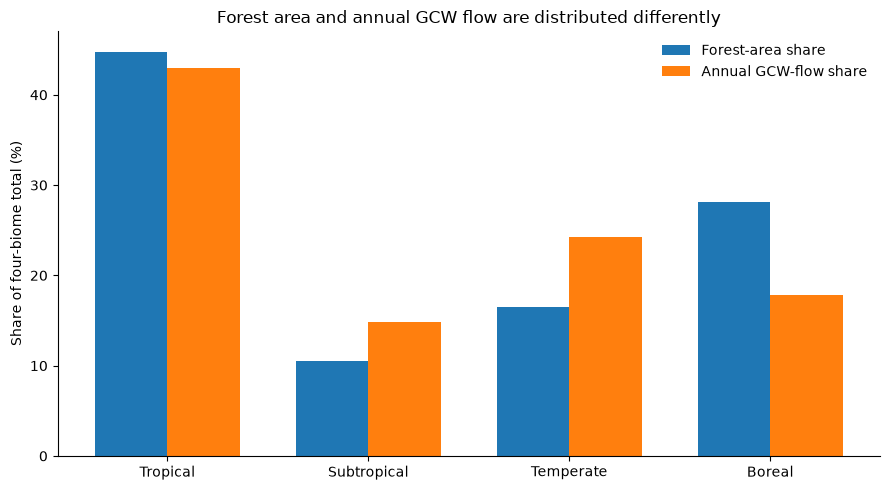

In [4]:
plot_biomes = biomes.copy()
plot_biomes["area_share_pct"] = 100 * plot_biomes["area_ha"] / plot_biomes["area_ha"].sum()
plot_biomes["flow_share_pct"] = 100 * plot_biomes["gross_additions_gtco2_yr"] / plot_biomes["gross_additions_gtco2_yr"].sum()

positions = np.arange(len(plot_biomes))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(positions - width / 2, plot_biomes["area_share_pct"], width, label="Forest-area share")
ax.bar(positions + width / 2, plot_biomes["flow_share_pct"], width, label="Annual GCW-flow share")
ax.set_xticks(positions, plot_biomes["biome"].str.title())
ax.set_ylabel("Share of four-biome total (%)")
ax.set_title("Forest area and annual GCW flow are distributed differently")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Separate spatial dispersion from account uncertainty

The spatial standard deviation describes how pixel-level rates vary within a biome. It is not a standard error or a confidence interval for the biome mean. The account's Monte Carlo uncertainty comes from separate inputs and is shown separately in the generated account tables.

In [5]:
display(rates[['biome', 'rate_tc_ha_yr_mean', 'rate_tc_ha_yr_spatial_sd', 'spatial_sd_interpretation']])

,biome,rate_tc_ha_yr_mean,rate_tc_ha_yr_spatial_sd,spatial_sd_interpretation
0,tropical,0.934399,0.926969,spatial dispersion; not an estimate of rate un...
1,subtropical,1.370738,1.322735,spatial dispersion; not an estimate of rate un...
2,temperate,1.430069,0.801324,spatial dispersion; not an estimate of rate un...
3,boreal,0.618633,0.261215,spatial dispersion; not an estimate of rate un...


## 5. Compare the selected rates with Pan

The Pan comparison provides a published benchmark where the biome definitions can be matched. It is descriptive: Gibbs/GFW remains the rate source used in this account, and the comparison does not recalibrate those rates.

In [6]:
pan = pd.read_csv(TABLES / 'Supplementary_Pan_rate_comparison.csv')
display(pan)

,biome,gibbs_gfw_rate_tc_ha_yr,gibbs_gfw_period,gibbs_gfw_source,pan_row,pan_rate_tc_ha_yr,pan_rate_sd_tc_ha_yr,pan_source,pan_period,comparison_note
0,boreal,0.618633,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",Boreal forest,0.278806,0.034851,Pan et al. (2024) Table 1 (2010-2019) / mean P...,2010-2019,Contextual comparison only: periods and source...
1,subtropical,1.370738,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",NaN,NaN,NaN,NaN,NaN,Contextual comparison only: periods and source...
2,temperate,1.430069,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",Temperate forest,0.865966,0.063674,Pan et al. (2024) Table 1 (2010-2019) / mean P...,2010-2019,Contextual comparison only: periods and source...
3,tropical,0.934399,2001-2023 mean annual rate,"Gibbs et al. (2025), Harvard Dataverse DOI 10....",All tropical forests,1.319406,0.214665,Pan et al. (2024) Table 1 (2010-2019) / mean P...,2010-2019,Contextual comparison only: periods and source...


## 6. Check the account before moving to GCW valuation

Review the four biome labels, area and rate units, the 44/12 conversion, source period, and the recalculated-versus-reported flow. This closes the physical forest-account step before the social cost of carbon is applied.

In [7]:
assert set(biomes['biome'].str.lower()) == {'tropical', 'subtropical', 'temperate', 'boreal'}
max_abs_difference = biomes['difference_gtco2_yr'].abs().max()
print({'four_biomes_present': True, 'max_abs_flow_difference_gtco2_yr': float(max_abs_difference)})

{'four_biomes_present': True, 'max_abs_flow_difference_gtco2_yr': 6.341393263585187}
